In [8]:
import sys
import time
import numpy as np
import pandas as pd
from scipy import*
from scipy import stats
from scipy import optimize
import matplotlib as plt
import matplotlib.cm as cm
import astropy.units as u
import scipy.interpolate as si
import matplotlib.colors as plc
import matplotlib.colorbar as plo
import matplotlib.colors as mpc
import matplotlib.pyplot as mpl
import matplotlib.colorbar as mpo
import mpl_toolkits.axisartist as AA
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.ticker import AutoMinorLocator
from matplotlib.ticker import MaxNLocator
from mpl_toolkits.axes_grid1 import host_subplot
from astropy.io.votable import parse_single_table
from astropy.cosmology import FlatLambdaCDM
import matplotlib.gridspec as gridspec
from scipy import interpolate
from scipy.optimize import curve_fit
from astropy.stats import poisson_conf_interval
from astropy.table import Table,Column
from astropy.io import fits
#import colorcet as cc
from radio_beam import Beam
import seaborn as sns
from astroML.plotting import MultiAxes

from matplotlib.ticker import ScalarFormatter
#np.set_printoptions(threshold=100000000000)
np.printoptions(threshold=np.inf)

# ----------------------------------------------------------
'''axis'''
mpl.rcParams['xtick.major.pad']= 10
mpl.rcParams['ytick.major.pad']= 10
mpl.rcParams['xtick.major.size']  = 7
mpl.rcParams['xtick.major.width'] = 2
mpl.rcParams['ytick.major.size']  = 7
mpl.rcParams['ytick.major.width'] = 3
mpl.rcParams['xtick.minor.size']  = 5
mpl.rcParams['xtick.minor.width'] = .5
mpl.rcParams['ytick.minor.size']  = 5
mpl.rcParams['ytick.minor.width'] = .5

mpl.rc('xtick', labelsize=25)
mpl.rc('ytick', labelsize=25)
mpl.rcParams['ps.useafm'] = True
mpl.rcParams['pdf.use14corefonts'] = True
mpl.rcParams['text.usetex'] = True
#mpl.rcParams['text.latex.unicode']=True

mpl.rcParams['axes.linewidth'] = 2.5 #set the value globally
#font = {'family' : 'monospace',
#        'weight' : 'bold',
#        'size'   : 'larger'}

font = {'family' : 'monospace',
    'weight' : 'bold',
    'size'   : 22}


mpl.rc('font', **{'family': 'serif', 'serif': ['Computer Modern']})

%config InlineBackend.figure = 'retina'
%matplotlib notebook
%matplotlib inline

if not sys.warnoptions:
    import warnings
    warnings.simplefilter("ignore")

In [2]:
import numpy as np
from matplotlib.pyplot import *
from astropy.io import fits
from astropy.wcs import WCS
from astropy.table import Table
import sys, time, os
import bdsf
sys.path.append("/idia/projects/supermightee/wrappers/")
from observations import *
import matplotlib.pyplot as mpl

In [3]:

rundir = '/idia/users/emmanuelocran/MIGHTEE_images/SARAO_Workshop/'
imagedir = rundir
srcdir   = rundir 
outdir   = srcdir
basename = 'MIGHTEE_Continuum_DR1_COSMOS_'+'5p2arcsec_I'+'_v1.1'
negfile = srcdir+basename+'.negative.fits'


fitsname = basename+'.fits'
#efreqname = 'superMIGHTEE_'+band+'_'+mosaic+'_r'+robust+'.efreq.fits'
fitsfile = imagedir+fitsname

outfilename = outdir+'sources.out'
outfile = open(outfilename,'w')


resfile = outdir+basename+'_gauss_resid.fits'
rmsfile = outdir+basename+'_rms.fits'
bkgfile = outdir+basename+'_bkg.fits'

print ("current directory: %s" % os.getcwd())


if os.path.isfile(fitsfile):
    print ("Fits file %s detected" % fitsfile)
#    print ("Efreq file: %s" % efreqfile)
else: 
    outline = ("cound not find file %s" % fitsfile)
    print(outline); outfile.write(outline+'\n')
    raise SystemExit("Program Stop: Missing input fits file!")
outfile.write("** Running analysis on : %s\n" % fitsfile)
outfile.flush()

forced = False

current directory: /users/emmanuelocran/Source Finding
Fits file /idia/users/emmanuelocran/MIGHTEE_images/SARAO_Workshop/MIGHTEE_Continuum_DR1_COSMOS_5p2arcsec_I_v1.1.fits detected


In [4]:


#--------------------------------- open original fits image and enter beam parameter---
hdulist_I = fits.open(fitsfile)#,mode='update')
tempdata = hdulist_I[0].data
print (tempdata.shape)
#for i in range(tempdata.shape[2]):      # uncomment this if image is padded with zeros instead of nans.
#    for j in range (tempdata.shape[3]):
#        if tempdata[0,0,i,j] == 0.0:
#            tempdata[0,0,i,j] = nan

Idata = tempdata#[0,:,:]
print ("Image dimension:", Idata.shape)
fitskeys= hdulist_I[0].header.keys()
nobeam = True

hdulist_I[0].header.remove('ALTRVAL',ignore_missing=True)
    
if 'BMAJ' in fitskeys:
    print ("Fits header has beam information. Setting nobeam to False")
    nobeam = False
#if (nobeam):
#    print ("no beam in header")
#    hdulist_I[0].header['BMAJ'] = beam.bmaj/3600.0
#    hdulist_I[0].header['BMIN'] = beam.bmin/3600.0
#    hdulist_I[0].header['BPA'] = beam.bpa
#else:
    bmaj = hdulist_I[0].header['BMAJ']*3600.0
    bmin = hdulist_I[0].header['BMIN']*3600.0
    bpa = hdulist_I[0].header['BPA']

print("In header BMAJ = %6.2f arcsec" % (3600.0*hdulist_I[0].header['BMAJ']))
print("In header BMIN = %6.2f arcsec" % (3600.0*hdulist_I[0].header['BMIN']))
print("In header BPA = %6.2f degrees" % (hdulist_I[0].header['BPA']))
#beam.show()
#outfile.write("bmaj = %6.2f, bmin = %6.2f, bpa = %5.1f\n" % (bmaj, bmin, bpa))

#print (hdulist_I[0].header)
#hdulist_I.flush()
#hdulist_I.close()
#outfile.flush()

# make an inverted image.  A source finding run on this image will provide an estimate of false positives
hdulist_I = fits.open(fitsfile)
hdulist_neg = hdulist_I                 
hdulist_neg[0].data = -1.0*hdulist_I[0].data
negdata = hdulist_neg[0].data#[0,0,:,:]

hdulist_neg.writeto(negfile,overwrite=True)
hdulist_I.close()



(7486, 7486)
Image dimension: (7486, 7486)
Fits header has beam information. Setting nobeam to False
In header BMAJ =   5.20 arcsec
In header BMIN =   5.20 arcsec
In header BPA =   0.00 degrees


In [5]:
startime = time.strftime("%a, %d %b %Y %H:%M:%S", time.localtime())
print ("Start at %s" % startime)
outfile.write("Start at %s\n" % startime)
process_start = time.time()

Start at Mon, 10 Aug 2026 23:24:24


In [8]:

marktime = time.time(); duration = (marktime - process_start)/60.0
outline = "pybdsf process image: time since start = %6.3f minutes" % (duration)
print (outline); outfile.write(outline+"\n")
lasttime = marktime
if forced:
#    if smoothed:
    img = bdsf.process_image(fitsname, quiet=True, atrous_do = False, adaptive_rms_box=True, rms_box = (40,13),
                             rms_box_bright = (33,11), output_all=True, indir=imagedir, outdir = srcdir,src_ra_dec = force_positions,
                             thresh_isl = 3.0, thresh_pix = 3.0)
else:
    img = bdsf.process_image(fitsfile, quiet=True, atrous_do = False, adaptive_rms_box=True, rms_box = (40,13),
                             rms_box_bright = (33,11), output_all=True,indir=imagedir,outdir = srcdir,
                             thresh_isl = 3.0, thresh_pix = 3.0, psf_vary_do = True)
#else:    
#os.chdir(srcdir)  ,  
marktime = time.time(); duration = (marktime - lasttime)/60.0
outline = "pybdsf process image complete: time to complete = %6.3f minutes" % (duration)
print (outline); #outfile.write(outline+"\n")
lasttime = marktime

print ('done running bdsf.process_image ...')
img.write_catalog(catalog_type = 'srl',format='fits',outfile=srcdir+basename+'.srl.fits',clobber=True)
img.write_catalog(catalog_type = 'srl',format='ascii',outfile=srcdir+basename+'.ascii',clobber=True)
print ("Creating rms and residual images")
img.export_image(img_format='fits',img_type='rms',outfile=rmsfile,clobber=True)
img.export_image(img_format='fits',img_type='gaus_resid',outfile=resfile,clobber=True) 
img.export_image(img_format='fits',img_type='mean',outfile=bkgfile,clobber=True) 



pybdsf process image: time since start =  1.363 minutes


stty: 'standard input': Inappropriate ioctl for device
stty: 'standard input': Inappropriate ioctl for device
/usr/local/lib/python3.8/dist-packages/scipy/optimize/_minpack_py.py:492: RuntimeWarning: Number of calls to function has reached maxfev = 1400.
  warnings.warn(errors[info][0], RuntimeWarning)
stty: 'standard input': Inappropriate ioctl for device
stty: 'standard input': Inappropriate ioctl for device
stty: 'standard input': Inappropriate ioctl for device


pybdsf process image complete: time to complete = 22.288 minutes
done running bdsf.process_image ...
--> Wrote FITS file '/idia/users/emmanuelocran/MIGHTEE_images/SARAO_Workshop/MIGHTEE_Continuum_DR1_COSMOS_5p2arcsec_I_v1.1.srl.fits'
--> Wrote ASCII file '/idia/users/emmanuelocran/MIGHTEE_images/SARAO_Workshop/MIGHTEE_Continuum_DR1_COSMOS_5p2arcsec_I_v1.1.ascii'
Creating rms and residual images
--> Wrote file '/idia/users/emmanuelocran/MIGHTEE_images/SARAO_Workshop/MIGHTEE_Continuum_DR1_COSMOS_5p2arcsec_I_v1.1_rms.fits'
--> Wrote file '/idia/users/emmanuelocran/MIGHTEE_images/SARAO_Workshop/MIGHTEE_Continuum_DR1_COSMOS_5p2arcsec_I_v1.1_gauss_resid.fits'
--> Wrote file '/idia/users/emmanuelocran/MIGHTEE_images/SARAO_Workshop/MIGHTEE_Continuum_DR1_COSMOS_5p2arcsec_I_v1.1_bkg.fits'


True

In [6]:
# load source data arrays
t=Table.read(srcdir+basename+'.srl.fits')
print("Finished reading table")
#for name in t.colnames:
#    print (name)

src_id = np.array(t['Source_id'])
ra = np.array(t['RA'])
raerr = np.array(t['E_RA'])
dec = np.array(t['DEC'])
decerr = np.array(t['E_DEC'])
peak = np.array(t['Peak_flux'])
dpeak = np.array(t['E_Peak_flux'])
flux = np.array(t['Total_flux'])
dflux = np.array(t['E_Total_flux'])
Smaj = 3600.0*np.array(t['Maj'])
dmaj = 3600.0*np.array(t['E_Maj'])
Smin = 3600.0*np.array(t['Min'])
dmin = 3600.0*np.array(t['E_Min'])
Spa = np.array(t['PA'])
dpa = np.array(t['E_PA'])

outline = ("pybdsf found %d sources" % (len(ra)))
print (outline); outfile.write(outline+"\n")
outline = ("Max flux: %10.1f microJy" % (1e06*flux.max()))
print (outline); outfile.write(outline+"\n")
outline = ("Min flux: %10.1f microJy" % (1e06*flux.min()))
print (outline); outfile.write(outline+"\n")
outfile.flush()

Finished reading table
pybdsf found 28161 sources
Max flux:   347142.4 microJy
Min flux:        4.7 microJy


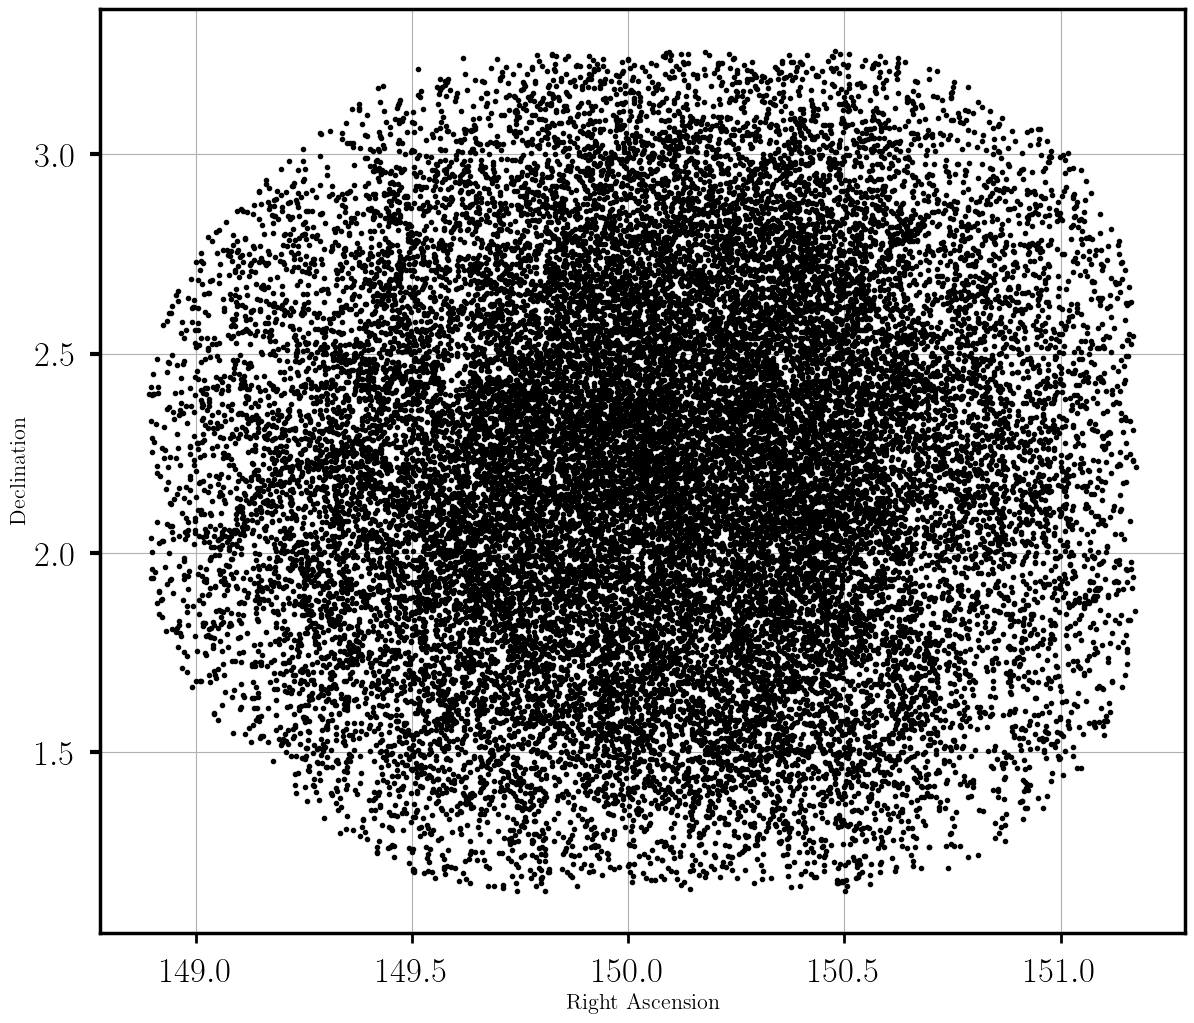

In [7]:
# plot sourced fitted amplitude against peak amplitude in the image
figure(figsize=(14,12))
xlabel('Right Ascension',fontsize=16)
ylabel('Declination',fontsize=16)
plot(ra,dec,'k.')
grid(True)
savefig(srcdir+'positions.png')
show()


In [9]:
#--------------------------------- open fits files for original and rms images --------
hdulist_I = fits.open(fitsfile)
Idata = hdulist_I[0].data
Ishape = Idata.shape
print (Ishape)
#Idata = hdulist_I[0].data[0,:,:]
hdulist_r = fits.open(rmsfile)
rmsdata=hdulist_r[0].data[0]
Imax = Idata.max()
print ("maximum Stokes I = %7.4f" % Imax)
meanrms = 1.0e06*np.nanmean(rmsdata)
medianrms = 1.0e06*np.nanmedian(rmsdata)
minrms = 1.0e06*np.nanmin(rmsdata)
outline = ("   mean of rms image = %7.2f microJy/bm" % meanrms)
print (outline); outfile.write(outline+"\n")
outline = (" median of rms image = %7.2f microJy/bm" % medianrms)
print (outline); outfile.write(outline+"\n")
outline = ("minimum of rms image = %7.2f microJy/bm" % minrms)
print (outline); outfile.write(outline+"\n")
w = WCS(hdulist_I[0].header)
outfile.flush()

(7486, 7486)
maximum Stokes I =     nan
   mean of rms image =    7.75 microJy/bm
 median of rms image =    5.71 microJy/bm
minimum of rms image =    1.63 microJy/bm


Found 10954712 nans in 56040196 pixels
Most probable value of rms dist: 2.781 microJy/bm


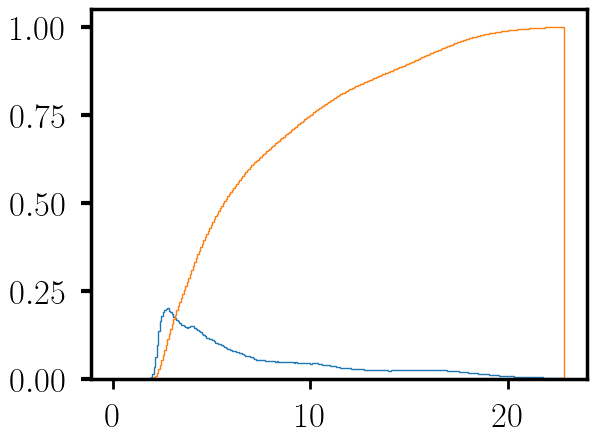

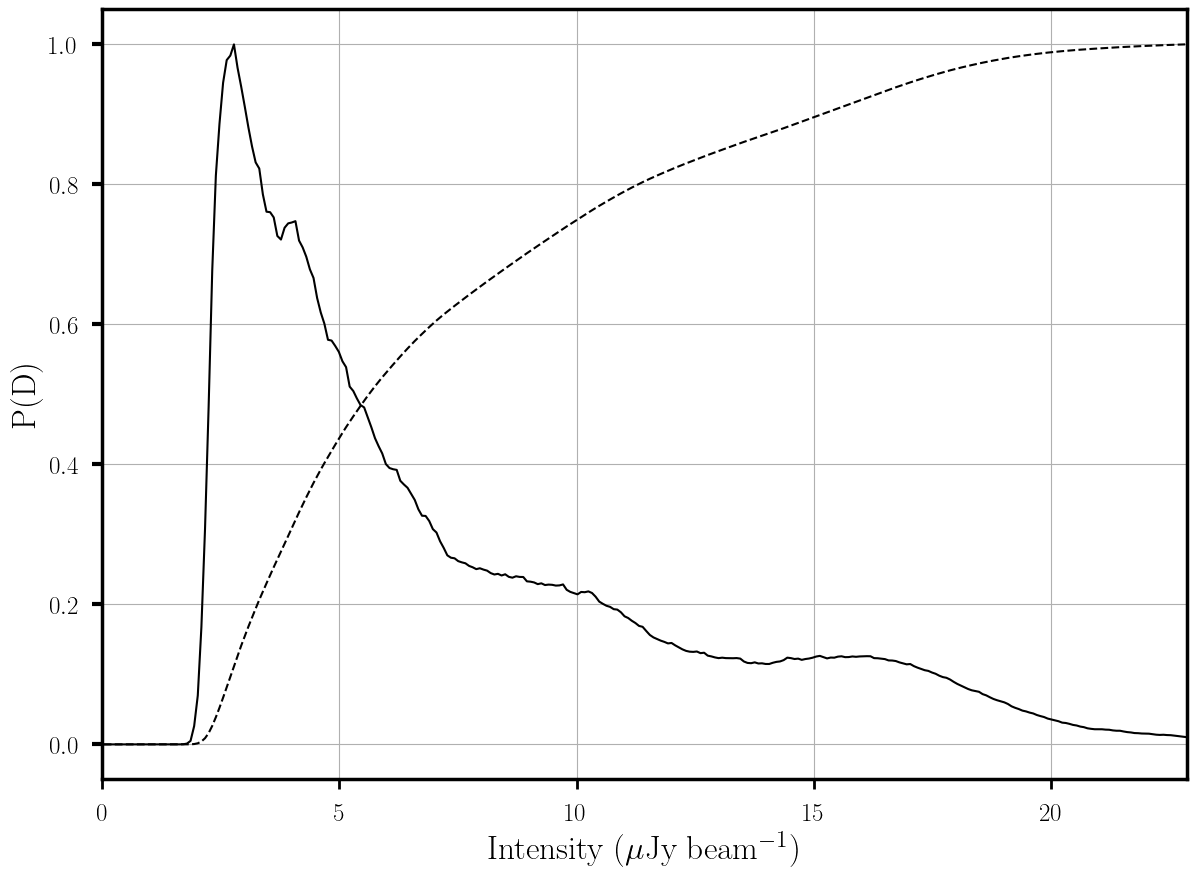

In [10]:

bincfit = []; num = []; numc = []
xrange = (0,4.0*medianrms)

values = 1e+06*np.ravel(rmsdata)
valid = values[np.invert(np.isnan(values))]
print ("Found %d nans in %d pixels" % ((len(values) - len(valid),len(values))))
nonzero = np.where(valid != 0) 
values = np.take(valid, nonzero)
values = np.ravel(values)

n,bins,patches = hist(values,bins=300, range = xrange, histtype='step', density = True)
nc,binsc,patches = hist(values,bins=300, range = xrange, histtype='step', density = True, cumulative=True)

for i in range(len(bins) - 1 ):
    bincentre =  (bins[i] + bins[i+1])/2.0 
    if(bincentre > xrange[0]) and (bincentre < xrange[1]):
        bincfit.append(bincentre)
        num.append(n[i]) 
        numc.append(nc[i])
    
j = np.argmax(num)
maxprob = bincfit[j]
outline = "Most probable value of rms dist: %5.3f microJy/bm" % maxprob
print (outline); outfile.write(outline+"\n")

factor = 1.0/np.max(np.array(num))
y = factor*np.array(num)
#titlestring = 'Histogram of rms image for: '+fitsname+': Most Prob. = '+ ("%6.2f" % maxprob)+', mean =  '+ ("%6.2f" % meanrms)+ ', median = ' + ("%6.2f" % medianrms)+' $\mu$Jy'  
figure(figsize= (14,10) )
#title(titlestring,fontsize=12)
tick_params(labelsize=18)
#xticks(fontsize=16)
#yticks(fontsize=16)
plot(bincfit,y,'k-')
plot(bincfit,numc,'k--',label='cumulative')
xlabel('Intensity ($\mu$Jy beam$^{-1}$)',fontsize=24)
xlim(0,xrange[1])
ylabel('P(D)', fontsize=24)

grid(True)
#legend(fontsize=14)
savefig(srcdir+basename+'.distribution.rms.pdf')
show()
outfile.flush()